In [1]:
#mount the drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt



In [3]:
#Define project path

base_path = "/content/drive/MyDrive/Capstone Project/Datasets"

print(os.listdir(base_path))

['Cow data.zip', 'Goat Pox Detection.v1i.tensorflow.zip']


In [4]:
#Create a working directory

working_path = "/content/pentai_data"

os.makedirs(working_path, exist_ok=True)

### Critical cleaning: persistent review outputs
These are document exclusions; they do **not** modify the original ZIPs or images.

In [5]:
# Critical cleaning review outputs (stored on Google Drive, NOT /content)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

review_dir = Path(base_path).parent / "outputs" / "data_quality"
review_dir.mkdir(parents=True, exist_ok=True)
print("Cleaning review directory:", review_dir)


Cleaning review directory: /content/drive/MyDrive/Capstone Project/outputs/data_quality


In [6]:
#Extract cow data
cow_zip_path = os.path.join(base_path, "Cow data.zip")
cow_extract_path = os.path.join(working_path, "cow_data")

with zipfile.ZipFile(cow_zip_path, 'r') as zip_ref:
    zip_ref.extractall(cow_extract_path)

print("Cow dataset extracted successfully!")

Cow dataset extracted successfully!


In [7]:
#Extract goat data
goat_zip_path = os.path.join(base_path, "Goat Pox Detection.v1i.tensorflow.zip")
goat_extract_path = os.path.join(working_path, "goat_data")

with zipfile.ZipFile(goat_zip_path, 'r') as zip_ref:
    zip_ref.extractall(goat_extract_path)

print("Goat dataset extracted successfully!")

Goat dataset extracted successfully!


In [8]:
#Function to show the folder structure
def show_folder_structure(path, max_depth=3):
    for root, dirs, files in os.walk(path):
        level = root.replace(path, '').count(os.sep)

        if level < max_depth:
            indent = ' ' * 4 * level
            print(f"{indent}{os.path.basename(root)}/")

            subindent = ' ' * 4 * (level + 1)
            for file in files[:5]:
                print(f"{subindent}{file}")




In [9]:
show_folder_structure(cow_extract_path)

cow_data/
    Lumpy Skin Images Dataset/
        Lumpy Skin/
            Lumpy_Skin_136.png
            Lumpy_Skin_97.png
            Lumpy_Skin_245.png
            Lumpy_Skin_207.png
            Lumpy_Skin_143.png
        Normal Skin/
            Normal_Skin_482.png
            Normal_Skin_484.png
            Normal_Skin_190.png
            Normal_Skin_198.png
            Normal_Skin_155.png


In [10]:
show_folder_structure(goat_extract_path)

goat_data/
    README.roboflow.txt
    train/
        healthy9_png.rf.7fb0146f0d2c0bdc70ce9f359e511bf6.jpg
        healthy382_png.rf.a1f0bca14e2d73a41524f53ef1363fd9.jpg
        goat_pox125_png.rf.021f51f6fed16484423d65b73c52b0e6.jpg
        healthy982_png.rf.d58ef3447e541d6eeb762110c06283ab.jpg
        goat_pox56_png.rf.2cc1a8096267a1dec5201268e974495f.jpg
    valid/
        healthy422_png.rf.18b83ca512413e3bd791be1052323459.jpg
        healthy258_png.rf.26b5f31897b922a81d8890a682d3194c.jpg
        healthy244_png.rf.3fb7c73ffa96c6d8bfa889af7104c6a0.jpg
        healthy520_png.rf.85f6177b2dcb65e3168477e9015bc608.jpg
        healthy551_png.rf.90637826a84ec92aeba725b2188a654f.jpg
    test/
        goat_pox81_png.rf.055f53aeab9a402fa6e3739aac33696e.jpg
        healthy51_png.rf.87cada35b3e51c7d69f3e91fd834d03b.jpg
        goat_pox105_png.rf.7d9452238409699f19b7b18221236447.jpg
        healthy829_png.rf.e5bdbb46d25c9c7b7a37a4f9ddbdd5b7.jpg
        goat_pox389_png.rf.da74e2dab18f79ee0027a7d9f

In [11]:


train_annotations_path = os.path.join(
    goat_extract_path,
    "train",
    "_annotations.csv"
)

train_annotations = pd.read_csv(train_annotations_path)

print(train_annotations.head())

                                            filename  width  height  \
0  goat_pox241_png.rf.c81588fb50b7b301b89f7efca1c...    600     450   
1  goat_pox210_png.rf.8bc49daaf80ba31aa8545ec22b2...    283     178   
2  goat_pox369_png.rf.6e5021d6879798785a581ec2bf5...    200     200   
3  goat_pox236_png.rf.ef3f2dc64789a902b1f4b775872...    416     416   
4  healthy412_png.rf.542a8898eb5f41576a72de53ac29...    640     640   

          class  xmin  ymin  xmax  ymax  
0       goatpox   141    90   565   396  
1       goatpox    18    43   186   178  
2       goatpox     0     2   161   200  
3       goatpox    75   116   278   416  
4  healthy_skin   204   110   506   611  


In [12]:
print(train_annotations["class"].value_counts(dropna=False))

class
healthy_skin    442
goatpox         392
Name: count, dtype: int64


In [13]:
print("Unique images:", train_annotations["filename"].nunique())
print("Total annotation rows:", len(train_annotations))

Unique images: 705
Total annotation rows: 834


In [14]:
healthy_rows = train_annotations[
    train_annotations["filename"].str.lower().str.startswith("healthy")
]

print(healthy_rows.head(10))

print("\nHealthy class values:")
print(healthy_rows["class"].value_counts(dropna=False))

                                             filename  width  height  \
4   healthy412_png.rf.542a8898eb5f41576a72de53ac29...    640     640   
13  healthy119_png.rf.e54990c6ed72b4adcee15ca6b52f...   1024     681   
14  healthy130_png.rf.c5e58774d243c6bcc9868f215b74...    683     683   
17  healthy560_png.rf.2a1e87e66631c8a7685f1f5e4cbf...    590     505   
18  healthy810_png.rf.f1966f6c3904880cf7e283d37b03...    768     768   
19  healthy39_png.rf.8582941ecde298b585043b486423c...   1024     768   
24  healthy615_png.rf.f308ceef3b669ff6e94fa386bec6...   1024     731   
26  healthy143_png.rf.c30474771086881f7231f1a46568...    910    1024   
27  healthy616_png.rf.6b25412db25392905060ef489a07...   1024     685   
30  healthy569_png.rf.2dea3a3bab04f7ff268993399568...   1024     768   

           class  xmin  ymin  xmax  ymax  
4   healthy_skin   204   110   506   611  
13  healthy_skin   439    45  1024   681  
14  healthy_skin    85     4   605   679  
17  healthy_skin    22    11   572 

### Goat filename / annotation discrepancy
Two images have filenames beginning with `healthy`, but the source annotations mark `goatpox`. This does **not** establish a misclassification. Verify the annotations against source evidence before approving or changing labels.

In [15]:
#Create one label per goat image
def create_image_level_labels(annotation_df):
    image_labels = []

    for filename, group in annotation_df.groupby("filename"):

        classes = group["class"].unique()

        # If goatpox appears anywhere in the image annotations,
        # classify the image as goatpox
        if "goatpox" in classes:
            image_label = "goatpox"
        else:
            image_label = "healthy"

        image_labels.append({
            "filename": filename,
            "class": image_label
        })

    return pd.DataFrame(image_labels)


train_goat_labels = create_image_level_labels(train_annotations)

train_goat_labels.head()

,filename,class
0,goat_pox100_png.rf.8bf80285dd817f97b2996cb0169...,goatpox
1,goat_pox102_png.rf.724dc0e7aaa0ab1e302f3e629aa...,goatpox
2,goat_pox103_png.rf.8fccbfee64e26e5a332e1956853...,goatpox
3,goat_pox104_png.rf.8460704c01b7d3efd7645d877bd...,goatpox
4,goat_pox106_png.rf.791baa199ca113b3a9ed362017b...,goatpox


In [16]:
#actual image-level class
print(train_goat_labels["class"].value_counts())

print("\nTotal unique images:")
print(len(train_goat_labels))

class
healthy    423
goatpox    282
Name: count, dtype: int64

Total unique images:
705


In [17]:
#Investigate the two misclassified  images
suspicious_images = train_annotations[
    (train_annotations["filename"].str.lower().str.startswith("healthy")) &
    (train_annotations["class"] == "goatpox")
]

print(suspicious_images)

                                              filename  width  height  \
296  healthy832_png.rf.8d4a401bd5ca7ce04418a6c989a5...    960     540   
618  healthy23_png.rf.ff44a1e2cf0423cb9c9be8f0d3361...    768    1024   

       class  xmin  ymin  xmax  ymax  
296  goatpox    46    15   625   540  
618  goatpox   142   166   664   845  


### Review goat filename / annotation disagreements
The following images are provisionally quarantined until their labels are verified.

Suspicious goat images: 2


,split,filename,annotation_class,review_decision,verified_label,review_notes
0,train,healthy23_png.rf.ff44a1e2cf0423cb9c9be8f0d3361...,goatpox,pending,,
1,train,healthy832_png.rf.8d4a401bd5ca7ce04418a6c989a5...,goatpox,pending,,


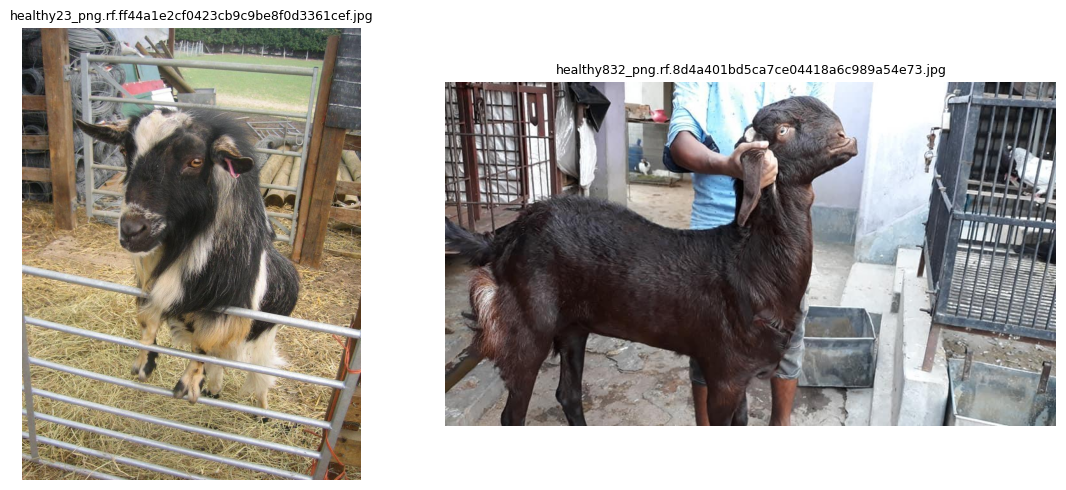

In [18]:
# Review filename/annotation disagreements; no diagnosis is inferred from filename
suspicious_filenames = sorted(suspicious_images["filename"].dropna().unique())
goat_annotation_review = pd.DataFrame([
    {"split": "train", "filename": name, "annotation_class": "goatpox",
     "review_decision": "pending", "verified_label": "", "review_notes": ""}
    for name in suspicious_filenames
])
goat_annotation_review.to_csv(review_dir / "goat_annotation_review.csv", index=False)
print("Suspicious goat images:", len(goat_annotation_review))
display(goat_annotation_review)

if suspicious_filenames:
    fig, axes = plt.subplots(1, len(suspicious_filenames),
                             figsize=(6 * len(suspicious_filenames), 5), squeeze=False)
    for idx, name in enumerate(suspicious_filenames):
        path = Path(goat_extract_path) / "train" / name
        with Image.open(path) as image:
            axes[0, idx].imshow(image.convert("RGB"))
        axes[0, idx].set_title(name[:60], fontsize=9)
        axes[0, idx].axis("off")
    plt.tight_layout()
    plt.show()


In [19]:
#Combinig all goat splits
def load_goat_annotations(base_path, split):

    annotation_path = os.path.join(
        base_path,
        split,
        "_annotations.csv"
    )

    annotations = pd.read_csv(annotation_path)

    image_labels = create_image_level_labels(annotations)
    image_labels["split"] = split

    return image_labels


goat_train = load_goat_annotations(goat_extract_path, "train")
goat_valid = load_goat_annotations(goat_extract_path, "valid")
goat_test = load_goat_annotations(goat_extract_path, "test")

goat_df = pd.concat(
    [goat_train, goat_valid, goat_test],
    ignore_index=True
)

goat_df["dataset"] = "goat"

goat_df.head()

,filename,class,split,dataset
0,goat_pox100_png.rf.8bf80285dd817f97b2996cb0169...,goatpox,train,goat
1,goat_pox102_png.rf.724dc0e7aaa0ab1e302f3e629aa...,goatpox,train,goat
2,goat_pox103_png.rf.8fccbfee64e26e5a332e1956853...,goatpox,train,goat
3,goat_pox104_png.rf.8460704c01b7d3efd7645d877bd...,goatpox,train,goat
4,goat_pox106_png.rf.791baa199ca113b3a9ed362017b...,goatpox,train,goat


In [20]:
print("Overall Goat Dataset:")
print(goat_df["class"].value_counts())

print("\nClass Distribution by Split:")
print(pd.crosstab(goat_df["split"], goat_df["class"]))

Overall Goat Dataset:
class
healthy    608
goatpox    398
Name: count, dtype: int64

Class Distribution by Split:
class  goatpox  healthy
split                  
test        36       63
train      282      423
valid       80      122


In [21]:
goat_class_summary = goat_df["class"].value_counts().reset_index()

goat_class_summary.columns = ["class", "count"]

goat_class_summary["percentage"] = (
    goat_class_summary["count"] /
    goat_class_summary["count"].sum() * 100
).round(2)

goat_class_summary

,class,count,percentage
0,healthy,608,60.44
1,goatpox,398,39.56


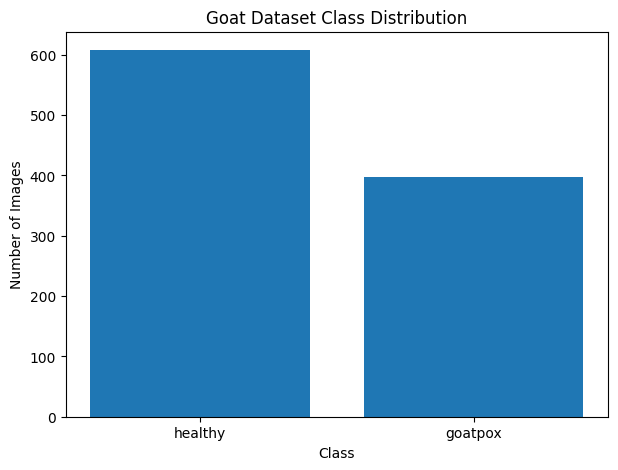

In [22]:

plt.figure(figsize=(7, 5))

plt.bar(
    goat_class_summary["class"],
    goat_class_summary["count"]
)

plt.title("Goat Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

In [23]:
from pathlib import Path

image_extensions = [".jpg", ".jpeg", ".png"]

for split in ["train", "valid", "test"]:

    split_path = Path(goat_extract_path) / split

    # Get actual image filenames
    actual_files = {
        file.name
        for file in split_path.iterdir()
        if file.suffix.lower() in image_extensions
    }

    # Get filenames from annotations
    annotated_files = set(
        goat_df[goat_df["split"] == split]["filename"]
    )

    # Find images not represented in annotations
    missing_from_annotations = actual_files - annotated_files

    print(f"\n{split.upper()} SPLIT")
    print(f"Actual image files: {len(actual_files)}")
    print(f"Annotated images: {len(annotated_files)}")
    print(
        f"Images missing from annotations: "
        f"{len(missing_from_annotations)}"
    )

    if missing_from_annotations:
        print(missing_from_annotations)


TRAIN SPLIT
Actual image files: 707
Annotated images: 705
Images missing from annotations: 2
{'healthy838_png.rf.2e6977b35614cce2ead67aac777b1bbc.jpg', 'healthy862_png.rf.c5980516823c71401655d3feea53ef2b.jpg'}

VALID SPLIT
Actual image files: 202
Annotated images: 202
Images missing from annotations: 0

TEST SPLIT
Actual image files: 100
Annotated images: 99
Images missing from annotations: 1
{'healthy815_png.rf.52908ccf872ad52f191148bdfd5d0816.jpg'}


### Export missing goat annotations
Unannotated files remain in the original archive but are provisionally excluded from classification.

In [24]:
# Reconcile all on-disk goat images with annotation records
exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
missing_rows = []
for split in ("train", "valid", "test"):
    split_dir = Path(goat_extract_path) / split
    actual = {p.name for p in split_dir.iterdir() if p.is_file() and p.suffix.lower() in exts}
    labelled = set(goat_df.loc[goat_df["split"].eq(split), "filename"])
    for filename in sorted(actual - labelled):
        missing_rows.append({"split": split, "filename": filename,
                             "review_decision": "exclude", "reason": "No annotation found"})
goat_missing_df = pd.DataFrame(missing_rows, columns=["split", "filename", "review_decision", "reason"])
goat_missing_df.to_csv(review_dir / "goat_missing_annotations.csv", index=False)
display(goat_missing_df)
print("Unannotated goat images:", len(goat_missing_df))


,split,filename,review_decision,reason
0,train,healthy838_png.rf.2e6977b35614cce2ead67aac777b...,exclude,No annotation found
1,train,healthy862_png.rf.c5980516823c71401655d3feea53...,exclude,No annotation found
2,test,healthy815_png.rf.52908ccf872ad52f191148bdfd5d...,exclude,No annotation found


Unannotated goat images: 3


In [25]:
#data quality summary
data_quality_summary = pd.DataFrame({
    "split": ["train", "valid", "test"],
    "actual_images": [707, 202, 100],
    "annotated_images": [705, 202, 99],
    "unlabeled_images": [2, 0, 1]
})

data_quality_summary

,split,actual_images,annotated_images,unlabeled_images
0,train,707,705,2
1,valid,202,202,0
2,test,100,99,1


Data Quality Finding: The goat dataset contains 1,009 image files, consistent with the dataset README. However, only 1,006 images are represented in the annotation files. Three images have no corresponding annotation records: two in the training split and one in the test split. These images will be excluded from the classification dataset.

##Image metadata analysis

In [26]:
from pathlib import Path

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

def get_image_files(folder_path):
    image_files = []

    for extension in image_extensions:
        image_files.extend(Path(folder_path).rglob(f"*{extension}"))
        image_files.extend(Path(folder_path).rglob(f"*{extension.upper()}"))

    return image_files

In [27]:
from PIL import Image
import pandas as pd

def get_image_metadata(image_paths):
    """
    Extract metadata from a list of image paths.
    """

    metadata = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                metadata.append({
                    "filepath": str(image_path),
                    "filename": image_path.name,
                    "width": img.width,
                    "height": img.height,
                    "format": img.format,
                    "mode": img.mode
                })

        except Exception as e:
            print(f"Could not read {image_path}: {e}")

    return pd.DataFrame(metadata)

### Cow image metadata analysis

In [28]:
cow_images = get_image_files(cow_extract_path)

print(f"Total cow images: {len(cow_images)}")

Total cow images: 1024


In [29]:
cow_metadata = get_image_metadata(cow_images)

cow_metadata.head()

,filepath,filename,width,height,format,mode
0,/content/pentai_data/cow_data/Lumpy Skin Image...,Lumpy_Skin_136.png,256,256,PNG,RGB
1,/content/pentai_data/cow_data/Lumpy Skin Image...,Lumpy_Skin_97.png,256,256,PNG,RGB
2,/content/pentai_data/cow_data/Lumpy Skin Image...,Lumpy_Skin_245.png,256,256,PNG,RGB
3,/content/pentai_data/cow_data/Lumpy Skin Image...,Lumpy_Skin_207.png,256,256,PNG,RGB
4,/content/pentai_data/cow_data/Lumpy Skin Image...,Lumpy_Skin_143.png,256,256,PNG,RGB


In [30]:
#Image dimensions
cow_metadata[["width", "height"]].describe()

,width,height
count,1024.0,1024.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0


In [31]:
#Image formats
print(cow_metadata["format"].value_counts())

format
PNG    1024
Name: count, dtype: int64


In [32]:
#Color modes
print(cow_metadata["mode"].value_counts())

mode
RGB     1011
RGBA      13
Name: count, dtype: int64


### Cow Dataset Metadata Findings

The cow dataset contains 1,024 PNG images.

Image format analysis shows that all images use PNG format,
indicating consistency in file formats.

Color mode analysis identified:
- 1,011 RGB images.
- 13 RGBA images.

The presence of RGBA images indicates that some images
contain an additional alpha channel for transparency.

During preprocessing, all images will be converted to RGB
to ensure consistent three-channel input for the CNN model.

Image dimensions will be further investigated to determine
whether resizing is necessary.

### Goat image metadata analysis

In [33]:
goat_images = get_image_files(goat_extract_path)

print(f"Total goat images: {len(goat_images)}")

Total goat images: 1009


In [34]:
#Extract goat image metadata
goat_metadata = get_image_metadata(goat_images)

goat_metadata.head()

,filepath,filename,width,height,format,mode
0,/content/pentai_data/goat_data/train/healthy9_...,healthy9_png.rf.7fb0146f0d2c0bdc70ce9f359e511b...,1024,768,JPEG,RGB
1,/content/pentai_data/goat_data/train/healthy38...,healthy382_png.rf.a1f0bca14e2d73a41524f53ef136...,1536,2048,JPEG,RGB
2,/content/pentai_data/goat_data/train/goat_pox1...,goat_pox125_png.rf.021f51f6fed16484423d65b73c5...,259,194,JPEG,RGB
3,/content/pentai_data/goat_data/train/healthy98...,healthy982_png.rf.d58ef3447e541d6eeb762110c062...,1152,1548,JPEG,RGB
4,/content/pentai_data/goat_data/train/goat_pox5...,goat_pox56_png.rf.2cc1a8096267a1dec5201268e974...,416,416,JPEG,RGB


In [35]:
#Check image formats
print("Goat image formats:")
print(goat_metadata["format"].value_counts())

Goat image formats:
format
JPEG    1009
Name: count, dtype: int64


In [36]:
#Check color modes
print("Goat image color modes:")
print(goat_metadata["mode"].value_counts())

Goat image color modes:
mode
RGB    1009
Name: count, dtype: int64


In [37]:
#Check image dimensions
goat_metadata[["width", "height"]].describe()

,width,height
count,1009.000000,1009.000000
mean,734.711596,642.500496
std,429.057882,397.822623
min,194.000000,159.000000
25%,416.000000,416.000000
50%,698.000000,674.000000
75%,1024.000000,768.000000
max,2048.000000,2048.000000


## Goat Dataset Metadata Analysis

The goat dataset contains 1,009 images.

### Image Formats
All images are in JPEG format, indicating consistent file formats.

### Color Modes
All images use RGB color mode, meaning they contain three color channels.

### Image Dimensions
The images have varying dimensions:

- Minimum width: 194 pixels
- Maximum width: 2,048 pixels
- Average width: approximately 735 pixels
- Minimum height: 159 pixels
- Maximum height: 2,048 pixels
- Average height: approximately 643 pixels

### Conclusion

The goat dataset has consistent image formats and color modes.
However, image dimensions vary considerably.

During preprocessing, images will be resized to a
consistent input size suitable for the selected CNN architecture.

In [38]:
#Check for corrupted images
from PIL import Image

def find_corrupted_images(image_paths):
    corrupted = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted.append(str(image_path))

    return corrupted


In [39]:
corrupted_cow = find_corrupted_images(cow_images)

print("Corrupted cow images:", len(corrupted_cow))

Corrupted cow images: 0


In [40]:
corrupted_goat = find_corrupted_images(goat_images)

print("Corrupted goat images:", len(corrupted_goat))

Corrupted goat images: 0


No corrupted images  for both cows and goats were identified during this analysis.

In [41]:
#Check for duplicates
import hashlib

def find_duplicates(image_paths):

    hashes = {}
    duplicates = []

    for image_path in image_paths:
        try:
            with open(image_path, "rb") as file:
                image_hash = hashlib.md5(file.read()).hexdigest()

            if image_hash in hashes:
                duplicates.append({
                    "duplicate": str(image_path),
                    "original": str(hashes[image_hash])
                })
            else:
                hashes[image_hash] = image_path

        except Exception as e:
            print(f"Error processing {image_path}: {e}")

    return duplicates

In [42]:
cow_duplicates = find_duplicates(cow_images)

print("Cow duplicates:", len(cow_duplicates))

Cow duplicates: 5


In [43]:
goat_duplicates = find_duplicates(goat_images)

print("Goat duplicates:", len(goat_duplicates))

Goat duplicates: 0


The cow dataset contains five duplicate occurrences detected through MD5 hashing.



No exact duplicate files were detected in the goat dataset.

In [44]:
# Inspect the five cow duplicates

cow_duplicates_df = pd.DataFrame(cow_duplicates)

cow_duplicates_df

,duplicate,original
0,/content/pentai_data/cow_data/Lumpy Skin Image...,/content/pentai_data/cow_data/Lumpy Skin Image...
1,/content/pentai_data/cow_data/Lumpy Skin Image...,/content/pentai_data/cow_data/Lumpy Skin Image...
2,/content/pentai_data/cow_data/Lumpy Skin Image...,/content/pentai_data/cow_data/Lumpy Skin Image...
3,/content/pentai_data/cow_data/Lumpy Skin Image...,/content/pentai_data/cow_data/Lumpy Skin Image...
4,/content/pentai_data/cow_data/Lumpy Skin Image...,/content/pentai_data/cow_data/Lumpy Skin Image...


In [45]:
for duplicate in cow_duplicates:
    original = duplicate["original"]
    copied = duplicate["duplicate"]

    original_class = Path(original).parent.name
    duplicate_class = Path(copied).parent.name

    print("Original:", Path(original).name)
    print("Original class:", original_class)
    print("Duplicate:", Path(copied).name)
    print("Duplicate class:", duplicate_class)
    print("-" * 50)

Original: Lumpy_Skin_285.png
Original class: Lumpy Skin
Duplicate: Lumpy_Skin_269.png
Duplicate class: Lumpy Skin
--------------------------------------------------
Original: Lumpy_Skin_318.png
Original class: Lumpy Skin
Duplicate: Lumpy_Skin_317.png
Duplicate class: Lumpy Skin
--------------------------------------------------
Original: Lumpy_Skin_86.png
Original class: Lumpy Skin
Duplicate: Normal_Skin_242.png
Duplicate class: Normal Skin
--------------------------------------------------
Original: Lumpy_Skin_154.png
Original class: Lumpy Skin
Duplicate: Normal_Skin_429.png
Duplicate class: Normal Skin
--------------------------------------------------
Original: Lumpy_Skin_229.png
Original class: Lumpy Skin
Duplicate: Normal_Skin_588.png
Duplicate class: Normal Skin
--------------------------------------------------


### Cattle duplicate review and provisional quarantine
Same-class exact duplicates: keep one image. Conflicting-label pairs: quarantine both images pending source verification.

,pair_id,original_relative_path,duplicate_relative_path,original_class,duplicate_class,conflict,review_decision,verified_label,review_notes
0,1,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin,Lumpy Skin,False,keep_original,,Exact same-class duplicate
1,2,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin,Lumpy Skin,False,keep_original,,Exact same-class duplicate
2,3,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin Images Dataset/Normal Skin/Normal_S...,Lumpy Skin,Normal Skin,True,exclude_pair,,Provisional quarantine: conflicting labels
3,4,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin Images Dataset/Normal Skin/Normal_S...,Lumpy Skin,Normal Skin,True,exclude_pair,,Provisional quarantine: conflicting labels
4,5,Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Ski...,Lumpy Skin Images Dataset/Normal Skin/Normal_S...,Lumpy Skin,Normal Skin,True,exclude_pair,,Provisional quarantine: conflicting labels


Conflicting pairs: 3


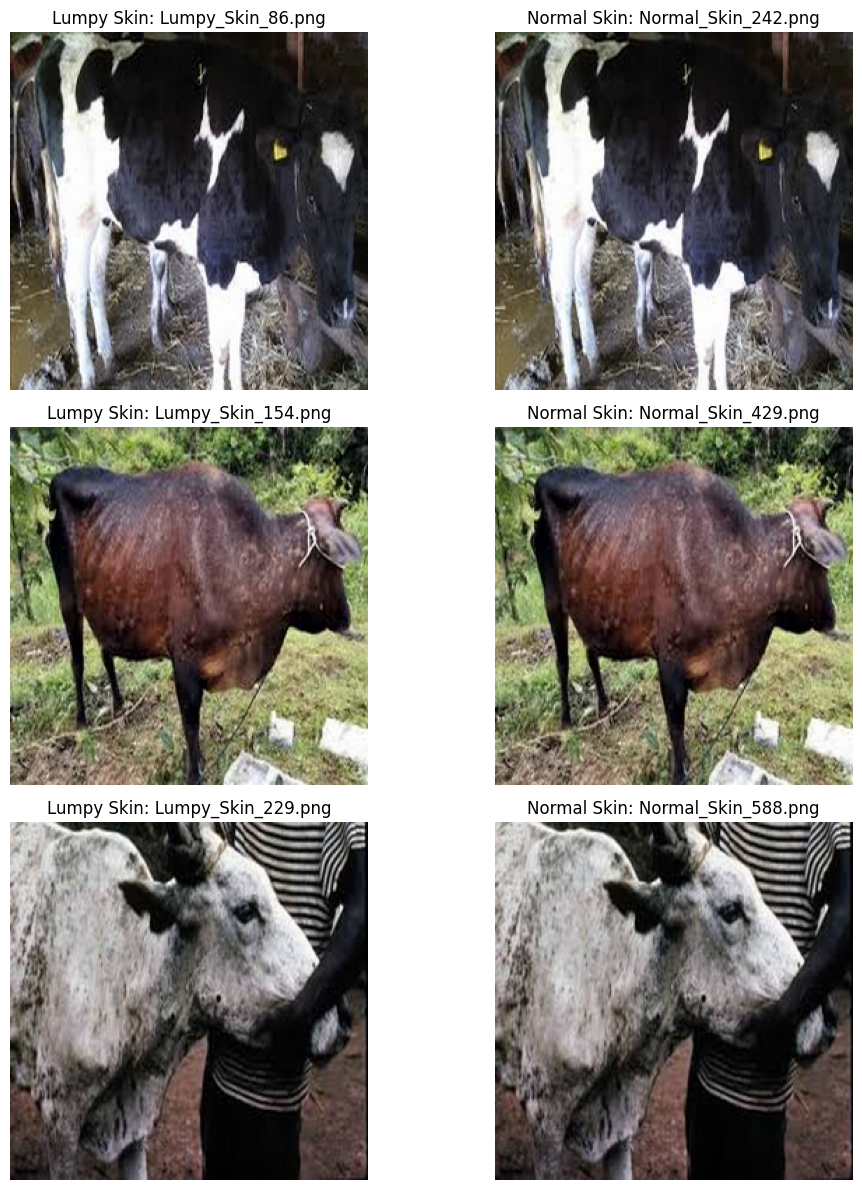

In [46]:
# Record duplicate pairs. No original image is renamed, moved or deleted.
cow_review_rows = []
for n, dup in enumerate(cow_duplicates, 1):
    original, duplicate = Path(dup["original"]), Path(dup["duplicate"])
    conflict = original.parent.name != duplicate.parent.name
    cow_review_rows.append({
        "pair_id": n, "original_relative_path": original.relative_to(Path(cow_extract_path)).as_posix(),
        "duplicate_relative_path": duplicate.relative_to(Path(cow_extract_path)).as_posix(),
        "original_class": original.parent.name, "duplicate_class": duplicate.parent.name,
        "conflict": conflict, "review_decision": "exclude_pair" if conflict else "keep_original",
        "verified_label": "", "review_notes": "Provisional quarantine: conflicting labels" if conflict else "Exact same-class duplicate"
    })
cow_review_df = pd.DataFrame(cow_review_rows)
cow_review_df.to_csv(review_dir / "cow_duplicate_review.csv", index=False)
display(cow_review_df)
print("Conflicting pairs:", int(cow_review_df["conflict"].sum()))

conflicts = cow_review_df.loc[cow_review_df["conflict"]]
if len(conflicts):
    fig, axes = plt.subplots(len(conflicts), 2, figsize=(11, 4 * len(conflicts)), squeeze=False)
    for row_idx, (_, r) in enumerate(conflicts.iterrows()):
        for col_idx, field in enumerate(("original_relative_path", "duplicate_relative_path")):
            path = Path(cow_extract_path) / r[field]
            with Image.open(path) as image:
                axes[row_idx, col_idx].imshow(image.convert("RGB"))
            axes[row_idx, col_idx].set_title(f"{path.parent.name}: {path.name}")
            axes[row_idx, col_idx].axis("off")
    plt.tight_layout()
    plt.show()




Cow dataset:
- Five duplicate pairs identified.
- Two pairs have identical class labels.
- Three pairs have conflicting class labels.

Goat dataset:
- No exact duplicate images identified.

### Data Quality Concerns

Three pairs of identical cow images were assigned different
class labels (Lumpy Skin and Normal Skin).

This indicates potential labeling inconsistencies.

### Recommended Actions

1. Retain one copy of same-class duplicate images.
2. Flag conflicting-label images for manual verification.
3. Exclude unresolved conflicting pairs from model development.
4. Preserve original files for traceability.

###Visual inspection

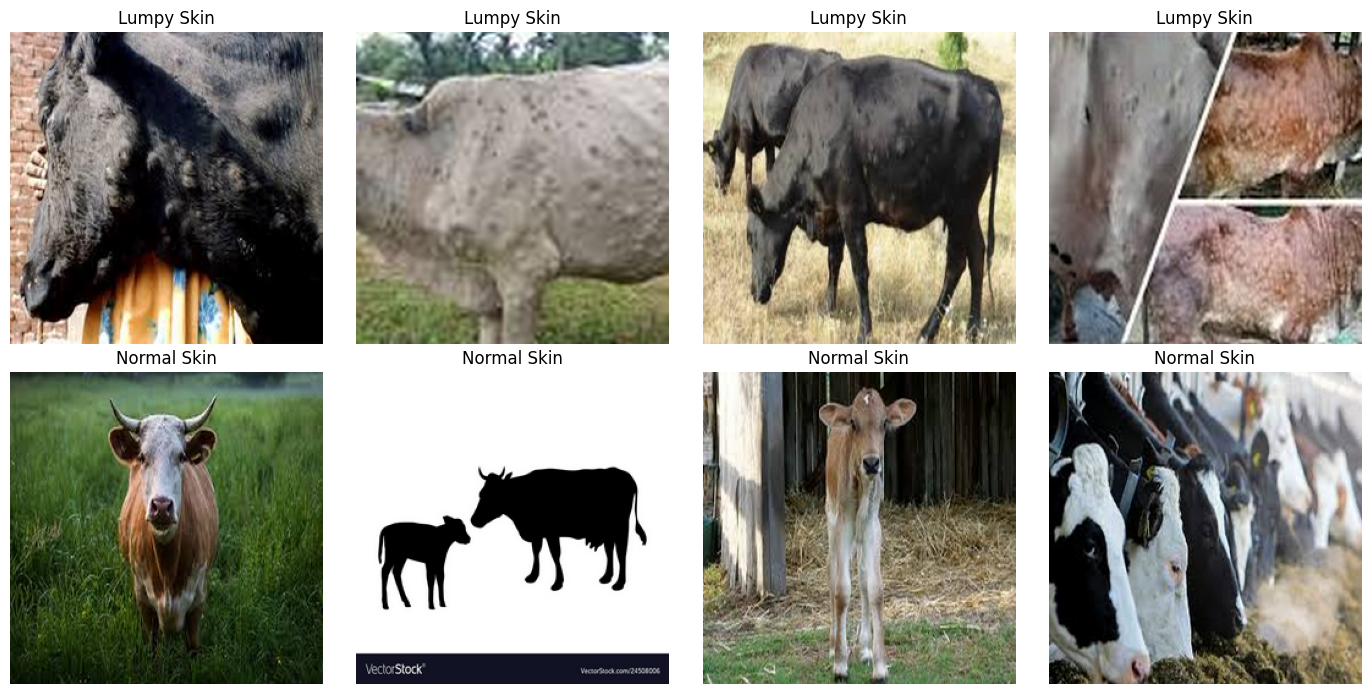

In [47]:
import matplotlib.pyplot as plt
from PIL import Image
import random

cow_classes = ["Lumpy Skin", "Normal Skin"]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(cow_classes):

    class_images = [
        path for path in cow_images
        if path.parent.name == class_name
    ]

    samples = random.sample(class_images, 4)

    for col, image_path in enumerate(samples):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

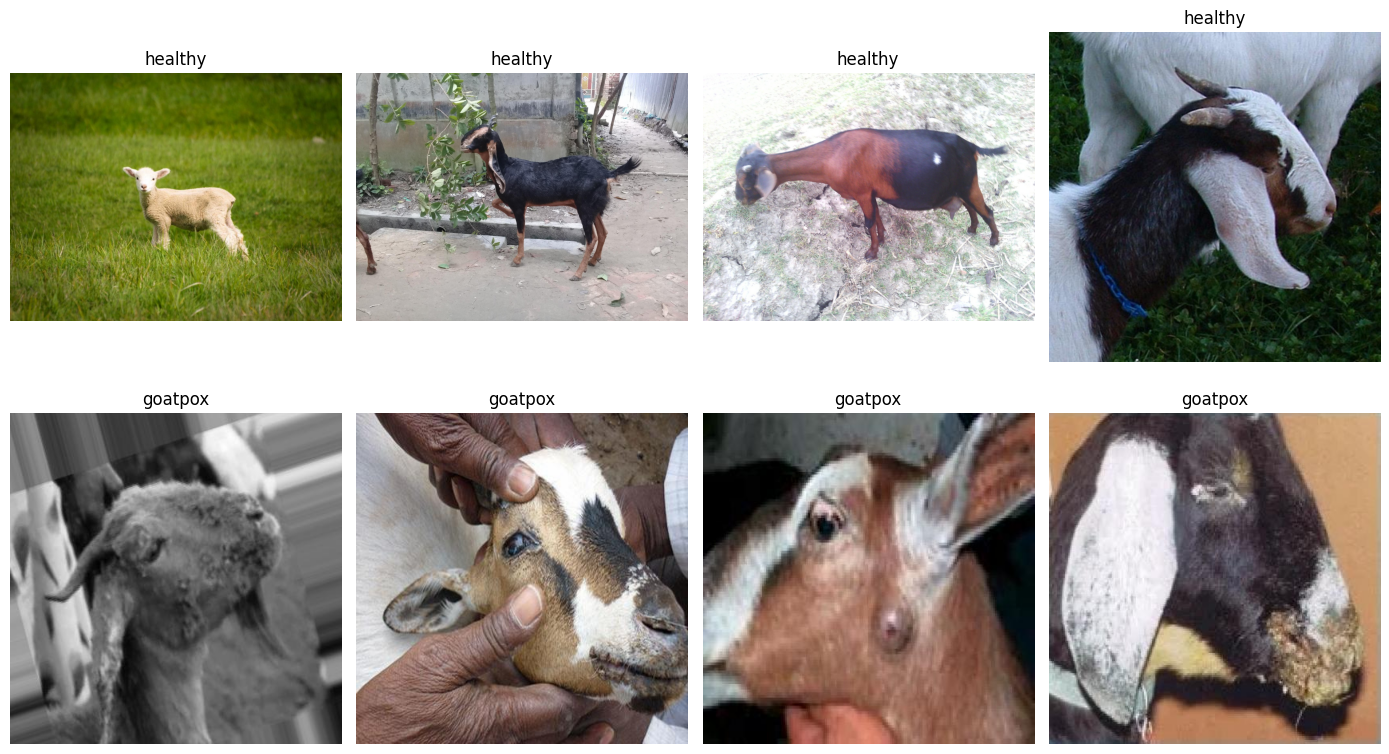

In [48]:
import matplotlib.pyplot as plt
import random
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for row, class_name in enumerate(["healthy", "goatpox"]):

    class_images = goat_df[
        goat_df["class"] == class_name
    ]["filename"].tolist()

    samples = random.sample(class_images, min(4, len(class_images)))

    for col, filename in enumerate(samples):

        image_path = Path(goat_extract_path) / goat_df[
            (goat_df["class"] == class_name) &
            (goat_df["filename"] == filename)
        ]["split"].iloc[0] / filename

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Final critical cleaning — cattle and goat manifests

**Run this cell only after:** (1) both datasets are extracted, (2) image metadata is created, (3) duplicate detection is complete, (4) `cow_review_df` is created, and (5) `goat_df`, `goat_annotation_review`, and `goat_missing_df` exist.

**What this does:** Keeps the original images untouched, excludes the two extra same-class cattle copies and both copies of each conflicting cattle pair, excludes three unannotated goat images and two unverified filename/annotation discrepancies, then validates and exports relative-path CSV manifests.

**Policy:** Unverified records are *quarantined*, not diagnosed or physically deleted. The output is **provisional** until the team approves the review log and checks remaining data quality and leakage. Expected counts based on earlier inspection: cattle 1,016 of 1,024; goats 1,004 of 1,009. If counts differ, investigate rather than changing assertions to force a pass.

In [49]:
# === CLEANING SUMMARY ===
# Original ZIP files and extracted images are NEVER edited or deleted here.
# A manifest is one row per source image with a Boolean 'include' flag.
# Cattle: two same-class extra copies excluded, plus BOTH sides of 3 label-conflict pairs.
# Goats: three missing-annotation images and two filename/annotation disagreements excluded.
# Only 'include == True' rows are eligible for a later preprocessing notebook.
from pathlib import Path
import pandas as pd

# 1. Build cattle inventory with portable, source-relative file paths.
cow_manifest = cow_metadata.copy()
cow_manifest["relative_path"] = cow_manifest["filepath"].map(
    lambda p: Path(p).relative_to(Path(cow_extract_path)).as_posix()
)
cow_labels = {"Lumpy Skin": "lumpy_skin", "Normal Skin": "healthy"}
cow_manifest["class"] = cow_manifest["relative_path"].map(
    lambda p: cow_labels.get(Path(p).parent.name)
)
if cow_manifest["class"].isna().any():
    raise ValueError("Unknown cattle class directory; review folder structure")
cow_manifest["include"] = True
cow_manifest["exclusion_reason"] = ""

# 2. Apply ALL duplicate decisions once, after cow_review_df has been created.
# No relabeling is attempted based on visual appearance or filename alone.
for _, item in cow_review_df.iterrows():
    original = item["original_relative_path"]
    duplicate = item["duplicate_relative_path"]
    if item["review_decision"] == "keep_original":
        excluded_paths = [duplicate]
        reason = "same_class_duplicate"
    elif item["review_decision"] == "exclude_pair":
        excluded_paths = [original, duplicate]
        reason = "conflicting_labels_unverified"
    else:
        raise ValueError(f"Unexpected cattle decision: {item['review_decision']}")
    matches = cow_manifest["relative_path"].isin(excluded_paths)
    if not matches.any():
        raise ValueError(f"Cattle duplicate paths not in inventory: {excluded_paths}")
    cow_manifest.loc[matches, "include"] = False
    cow_manifest.loc[matches, "exclusion_reason"] = reason

# 3. Build goat inventory using annotation-derived labels and original split assignments.
# Never re-split goat images in this notebook; their train/valid/test split is preserved.
goat_manifest = goat_df.copy()
goat_manifest["relative_path"] = goat_manifest.apply(
    lambda row: f"{row['split']}/{row['filename']}", axis=1
)
goat_manifest["include"] = True
goat_manifest["exclusion_reason"] = ""

# 4. Quarantine the two annotations whose 'healthy' filenames disagree with goatpox labels.
# The filename is NOT a reliable diagnosis; no arbitrary correction is made.
suspicious_keys = set(zip(goat_annotation_review["split"],
                          goat_annotation_review["filename"]))
suspect_mask = goat_manifest.apply(
    lambda row: (row["split"], row["filename"]) in suspicious_keys, axis=1
)
goat_manifest.loc[suspect_mask, "include"] = False
goat_manifest.loc[suspect_mask, "exclusion_reason"] = "annotation_filename_disagreement_unverified"

# 5. Add three unannotated goat files as excluded inventory records.
# These source files are recorded, not removed from disk.
missing_entries = [
    {"filename": row["filename"], "split": row["split"], "dataset": "goat",
     "class": pd.NA, "relative_path": f"{row['split']}/{row['filename']}",
     "include": False, "exclusion_reason": "missing_annotation"}
    for _, row in goat_missing_df.iterrows()
]
if missing_entries:
    goat_manifest = pd.concat([goat_manifest, pd.DataFrame(missing_entries)],
                              ignore_index=True)

# 6. Validate FIRST, save only if the full inventory and included paths check out.
for animal, manifest, original_paths, dataset_root in (
    ("cattle", cow_manifest, cow_images, cow_extract_path),
    ("goat", goat_manifest, goat_images, goat_extract_path),
):
    assert len(manifest) == len(original_paths), f"{animal}: inventory mismatch"
    assert manifest["relative_path"].is_unique, f"{animal}: repeated relative paths"
    eligible = manifest.loc[manifest["include"]]
    assert eligible["class"].notna().all(), f"{animal}: included image missing a label"
    assert all((Path(dataset_root) / p).is_file() for p in eligible["relative_path"]), (
        f"{animal}: at least one included image path does not exist"
    )
    print(f"{animal.upper()} | total={len(manifest)} | included={len(eligible)} "
          f"| excluded={len(manifest) - len(eligible)}")
    print("Included class distribution:\n", eligible["class"].value_counts().to_string())

# 7. Export with relative paths rather than transient Colab /content paths.
review_dir.mkdir(parents=True, exist_ok=True)
for animal, manifest in (("cow", cow_manifest), ("goat", goat_manifest)):
    portable = manifest.drop(columns=["filepath"], errors="ignore")
    portable.to_csv(review_dir / f"{animal}_cleaning_manifest.csv", index=False)
    portable.loc[portable["include"]].to_csv(
        review_dir / f"{animal}_eligible_manifest.csv", index=False
    )
print("Provisional cleaning manifests saved to:", review_dir)
print("STOP: Review and approve decisions before training or partition creation.")

CATTLE | total=1024 | included=1016 | excluded=8
Included class distribution:
 class
healthy       697
lumpy_skin    319
GOAT | total=1009 | included=1004 | excluded=5
Included class distribution:
 class
healthy    608
goatpox    396
Provisional cleaning manifests saved to: /content/drive/MyDrive/Capstone Project/outputs/data_quality
STOP: Review and approve decisions before training or partition creation.


In [50]:
from pathlib import Path

print("Output folder:", review_dir)

for file in sorted(Path(review_dir).glob("*.csv")):
    print(file.name)

Output folder: /content/drive/MyDrive/Capstone Project/outputs/data_quality
cow_approved_manifest.csv
cow_cleaning_manifest.csv
cow_duplicate_review.csv
cow_eligible_manifest.csv
goat_annotation_review.csv
goat_cleaning_manifest.csv
goat_eligible_manifest.csv
goat_missing_annotations.csv


# PentAI — Data Cleaning and Exploratory Data Analysis Summary

## 1. Project scope
Two image-classification tasks are retained: **cattle (Lumpy Skin vs healthy)** and **goats (goatpox vs healthy)**. Chicken images are out of scope. This notebook inspects and filters data; it does **not** train a model or create new cattle train/validation/test splits.

## 2. What the working analysis code does

| Code section | Purpose | Main result |
|---|---|---|
| Data mounting and ZIP extraction | Make the original cattle and goat datasets accessible in Colab | Working folders under `/content` |
| Folder and annotation inspection | Understand data layout and goat CSV labels | Original goat train/valid/test splits retained |
| Image-level goat labels | Combine multiple annotation rows into one image classification label | Healthy / goatpox per annotated image |
| Metadata inspection | Count actual files and inspect dimensions, formats and color modes | Cattle PNG and goat JPEG inventories |
| Corruption screening | Attempt to verify image files | Prior saved runs reported no detected corrupt images |
| Exact hashing | Identify identical file bytes | Five cattle duplicate pairs; no goat exact duplicates reported |
| Visual galleries | Display representative images | Images for human quality inspection |
| **Final critical cleaning cell** | **Exclude flagged records without deleting photos** | **Portable cattle and goat CSV manifests** |

## 3. Cleaning decisions and expected counts

The saved prior analysis reports **1,024 cattle images** and **1,009 goat image files**. The default conservative decisions are:

- **Cattle:** Two same-class duplicate copies are excluded, along with both images in each of three conflicting-label pairs (8 exclusions; **1,016 provisionally eligible**).
- **Goats:** Three files without annotation records are excluded, along with two training images whose filename suggests healthy while annotation indicates goatpox (5 exclusions; **1,004 provisionally eligible**).
- **No image is deleted.** Original ZIP archives and extracted image content remain unchanged. A manifest row records `relative_path`, `class`, `include`, and `exclusion_reason`; goat rows also retain `split`.

These counts are **expected from the original notebook outputs**, not new results until the revised notebook is rerun. Review logs and labels require team approval.

## 4. Code execution order — important

1. Mount Drive, import libraries, configure `base_path`, `working_path`, `review_dir`.
2. Extract BOTH datasets and inspect their structures.
3. Build `goat_df`, `goat_annotation_review`, `goat_missing_df`.
4. Build `cow_images`, `cow_metadata`, `goat_images`, `goat_metadata`.
5. Run corruption and duplicate checks to create `cow_duplicates` and `goat_duplicates`.
6. Create `cow_review_df` from cattle duplicate pairs.
7. **Run the final critical cleaning cell ONCE** after all the above variables exist.
8. Inspect the displayed counts and CSV files; document approval before progressing.

**Avoid** running old troubleshooting snippets that refer to `cow_manifest` before it exists. The final cleaning cell is now the only place that creates and filters both manifests.

## 5. Outputs and where to keep them

CSV files are written to Google Drive's `outputs/data_quality` directory near the dataset folder: `cow_cleaning_manifest.csv`, `cow_eligible_manifest.csv`, `goat_cleaning_manifest.csv`, and `goat_eligible_manifest.csv`, plus earlier duplicate and annotation review reports.

Commit the reviewed notebook under `notebooks/01_data_cleaning_and_eda.ipynb` and small *approved* portable reports under `reports/data_quality/`. Keep full image archives in shared data storage (not standard Git).

## 6. Remaining validation before declaring the data model-ready

- Confirm final labels and exclusion decisions with the team and source documentation.
- Check for visually similar or source-related images that could leak between splits.
- Preserve goat's original splits; verify their independence.
- Generate suitable cattle splits only after cleaning and leakage review, preferably in `02_preprocessing.ipynb`.
- Build model-specific RGB conversion, sizing and scaling in preprocessing; evaluate on held-out data later.